# Look at ancestor population

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import gzip
from Bio import SeqIO
import pysam
import collections

In [3]:
data_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/data"
fig_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/figures"

## Open sequencing files

In [4]:
for record in SeqIO.parse(data_path + '/ancestor/NL43_ann_wk0virusPassRef.fasta', "fasta"):
    seq_str = str(record.seq).upper()
    length = len(seq_str)
    print(f"ID: {record.id}, Length: {length}")
    print(f"Sequence: {seq_str}")


ID: NL43_ann_wk0virusPassRef, Length: 9707
Sequence: TGGAAGGGCTAATTCACTCCCAAAGAAGACAAGATATCCTTGATCTGTGGATCTACCACACACAAGGCTACTTCCCTGATTGGCAGAACTACACACCAGGGCCAGGGGTCAGATATCCACTGACCTTTGGATGGTGCTACAAGCTAGTACCAGTTGAGCCAGATAAGGTAGAAGAGGCCAATAAAGGAGAGAACACCAGCTTGTTACACCCTGTGAGCCTGCATGGAATGGATGACCCTGAGAGAGAAGTGTTAGAGTGGAGGTTTGACAGCCGCCTAGCATTTCATCACGTGGCCCGAGAGCTGCATCCGGAGTACTTCAAGAACTGCTGACATCGAGCTTGCTACAAGGGACTTTCCGCTGGGGACTTTCCAGGGAGGCGTGGCCTGGGCGGGACTGGGGAGTGGCGAGCCCTCAGATGCTGCATATAAGCAGCTGCTTTTTGCCTGTACTGGGTCTCTCTGGTTAGACCAGATCTGAGCCTGGGAGCTCTCTGGCTAACTAGGGAACCCACTGCTTAAGCCTCAATAAAGCTTGCCTTGAGTGCTCAAAGTAGTGTGTGCCCGTCTGTTGTGTGACTCTGGTAACTAGAGATCCCTCAGACCCTTTTAGTCAGTGTGGAAAATCTCTAGCAGTGGCGCCCGAACAGGGACTTGAAAGCGAAAGTAAAGCCAGAGGAGATCTCTCGACGCAGGACTCGGCTTGCTGAAGCGCGCACGGCAAGAGGCGAGGGGCGGCGACTGGTGAGTACGCCAAAAATTTTGACTAGCGGAGGCTAGAAGGAGAGAGATGGGTGCGAGAGCGTCGGTATTAAGCGGGGGAGAATTAGATAAATGGGAAAAAATTCGGTTAAGGCCAGGGGGAAAGAAACAATATAAACTAAAACATATAGTATGGGCAAGCAGGGAGCTAGAACGATTCGCAGTTAATCCTGGCCTTTTAGAGAC

In [5]:
lengths_1 = []

with gzip.open(data_path + '/ancestor/vsHIV1_NL4_3_R1.fastq.gz', "rt") as handle:
    for i, record in enumerate(SeqIO.parse(handle, "fastq")):
        if i < 2:
            sequence = str(record.seq)
            length = len(sequence)
            phred_scores = record.letter_annotations["phred_quality"]

            lengths_1.append(length)
            print(f"ID: {record.id}, Length: {length}")
            print(f"First 10 bases: {sequence[:10]}")
            print(f"First 10 Q-scores: {phred_scores[:10]}")

        
print(f"Number of sequences = {i}")
print(np.min(lengths_1), np.max(lengths_1))

ID: F158I-3FBF67:45:000000000-A3E4K:1:1102:13284:2053, Length: 251
First 10 bases: NGTACAGTAT
First 10 Q-scores: [2, 29, 29, 29, 16, 16, 31, 33, 35, 18]
ID: F158I-3FBF67:45:000000000-A3E4K:1:1102:13448:2091, Length: 251
First 10 bases: NGTCATGGTA
First 10 Q-scores: [2, 29, 16, 16, 16, 29, 18, 16, 33, 18]
Number of sequences = 80716
251 251


In [6]:
lengths_2 = []

with gzip.open(data_path + '/ancestor/vsHIV1_NL4_3_R2.fastq.gz', "rt") as handle:
    for i, record in enumerate(SeqIO.parse(handle, "fastq")):
        if i < 2:
            sequence = str(record.seq)
            length = len(sequence)
            phred_scores = record.letter_annotations["phred_quality"]

            lengths_2.append(length)
            print(f"ID: {record.id}, Length: {length}")
            print(f"First 10 bases: {sequence[:10]}")
            print(f"First 10 Q-scores: {phred_scores[:10]}")

        
print(f"Number of sequences = {i}")
print(np.min(lengths_2), np.max(lengths_2))

ID: F158I-3FBF67:45:000000000-A3E4K:1:1102:13284:2053, Length: 251
First 10 bases: TTCCTAATTG
First 10 Q-scores: [16, 16, 29, 32, 32, 18, 16, 16, 18, 35]
ID: F158I-3FBF67:45:000000000-A3E4K:1:1102:13448:2091, Length: 251
First 10 bases: ATTTTACACA
First 10 Q-scores: [29, 32, 16, 29, 32, 35, 37, 37, 37, 35]
Number of sequences = 80716
251 251


## Align raw sequences using BWA-MEM

In command line:   


bwa index reference.fasta  #Index the reference genome for BWA

samtools faidx reference.fasta  #Index the reference genome for Samtools (creates reference.fasta.fai)

bwa mem -t 4 reference.fasta R1.fastq.gz R2.fastq.gz | \
  samtools sort -@ 4 -o aligned_sorted.bam -   #Align reads, convert to BAM, and sort in a single pipeline

samtools index aligned_sorted.bam  # Index the sorted BAM file

## Process aligned BAM file

Creates a dataframe of all variants:
 - Position: reference genome position of variant, 0-based
 - Reference_allele: base in reference genome
 - New_allele: variant base 
 - Mutation_type: substitution, insertion or deletion
 - Count: number of reads with that variant
 - Depth: total number of reads at that position
 - Frequency: Count / Depth

In [7]:
bam = pysam.AlignmentFile(data_path + '/ancestor/aligned_sorted.bam', "rb")
for reference_name, length in zip(bam.references, bam.lengths):
    print(f"Chr: {reference_name}, Length: {length}")

Chr: NL43_ann_wk0virusPassRef, Length: 9707


In [8]:
#Quality thresholds
min_mapq = 30
min_baseq = 20
min_coverage = 10

#Open reference file
ref_fasta = pysam.FastaFile(data_path + '/ancestor/NL43_ann_wk0virusPassRef.fasta')

#Iterate through genome positions and record variants
rows = []

for pileupcolumn in bam.pileup(fastafile=ref_fasta, truncate=True, stepper="samtools"):

    #Get reference base at this position
    chrom = pileupcolumn.reference_name
    pos = pileupcolumn.reference_pos
    ref_base = ref_fasta.fetch(chrom, pos, pos + 1).upper()

    #Iterate through reads and keep counts in allele_counts
    allele_counts = collections.Counter()
    total_depth = 0

    for pileupread in pileupcolumn.pileups:

        #Mapping quality filter
        if pileupread.alignment.mapping_quality < min_mapq: 
            continue

        #Check for deletions covering this position
        if pileupread.is_del:
            allele_counts["DEL_SPAN"] += 1
            total_depth += 1
            continue

        #Check for skips in reference sequence
        if pileupread.is_refskip:
            continue

        #Base quality filter
        base_qual = pileupread.alignment.query_qualities[pileupread.query_position]
        if base_qual < min_baseq:
            continue

        #Identify SNVs, or indels
        total_depth += 1
        current_base = pileupread.alignment.query_sequence[pileupread.query_position].upper()

        #Insertions A->ATCG
        if pileupread.indel > 0:
            ins_seq = pileupread.alignment.query_sequence[pileupread.query_position+1 : pileupread.query_position+1+pileupread.indel].upper()
            alt_allele = ref_base + ins_seq
            allele_counts[("insertion", ref_base, alt_allele)] += 1

        #Deletions ATCG->A
        elif pileupread.indel < 0:
            del_len = abs(pileupread.indel)
            deleted_ref = ref_fasta.fetch(chrom, pos, pos + 1 + del_len).upper()
            allele_counts[("deletion", deleted_ref, ref_base)] += 1

        #SNVs A->T
        else:
            allele_counts[("substitution", ref_base, current_base)] += 1

    #Minimum coverage filter
    if total_depth < min_coverage:
        continue

    #Store recorded counts
    for key, count in allele_counts.items():
        if key == "DEL_SPAN": #Skip spanning deletions
            continue

        var_type, ref_allele, alt_allele = key
        if var_type == "substitution" and ref_allele == alt_allele: #Skip matching substitutions
            continue
        
        #Create dataframe row
        freq = count / total_depth
    
        row = {
        'Position': pos,
        'Reference_allele': ref_allele,
        'New_allele': alt_allele,
        'Mutation_type': var_type,
        'Count': count,
        'Depth': total_depth,
        'Frequency': round(freq, 4)
        }
        rows.append(row)

bam.close()
ref_fasta.close()

df = pd.DataFrame(rows)

In [9]:
df.head(5)

,Position,Reference_allele,New_allele,Mutation_type,Count,Depth,Frequency
0,465,T,A,substitution,1,11,0.0909
1,471,C,T,substitution,1,27,0.0370
2,497,C,G,substitution,1,76,0.0132
3,509,C,T,substitution,1,121,0.0083
4,514,T,C,substitution,1,120,0.0083


## Analyse variants

In [10]:
#Number of different variants
counts = df['Mutation_type'].value_counts()
for (variant, count) in counts.items():
    print(f"Number of {variant}s: {count}")

Number of substitutions: 12327
Number of deletions: 252
Number of insertions: 99


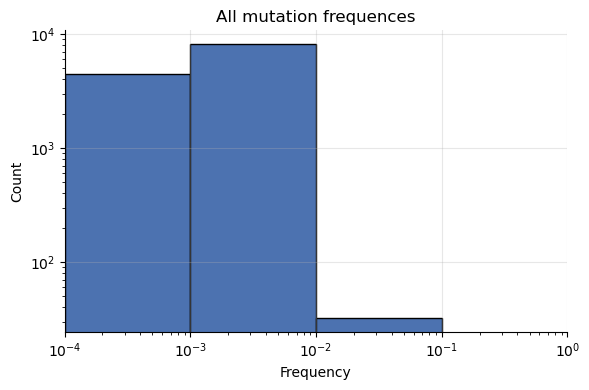

In [11]:
#Frequencies
fig, ax = plt.subplots(1,1,figsize=(6,4))
ax.hist(df['Frequency'],bins=[0,0.0001,0.001,0.01,0.1],color="#4C72B0",edgecolor='black')

#Format
ax.set_xlabel('Frequency')
ax.set_ylabel('Count')
ax.grid(alpha=0.3)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(0.0001,1)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('All mutation frequences')

plt.tight_layout()
plt.savefig(fig_path + "/ancestor_mutation_frequencies.pdf")
plt.show()

In [12]:
#Mutations above 1%
df_1_perc = df[df['Frequency']>0.01]
counts = df_1_perc['Mutation_type'].value_counts()
for (variant, count) in counts.items():
    print(f"Number of {variant}s: {count}")

Number of substitutions: 30
Number of insertions: 1


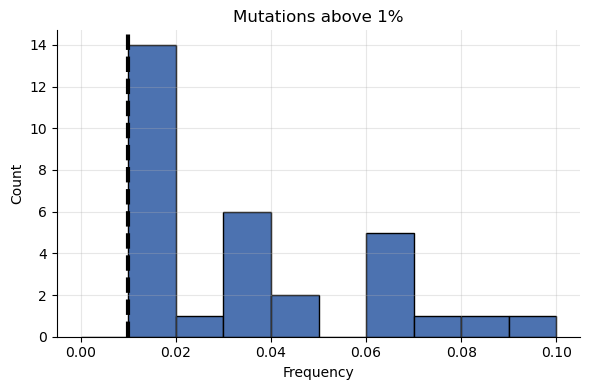

In [13]:
#Frequencies
fig, ax = plt.subplots(1,1,figsize=(6,4))
ax.hist(df_1_perc['Frequency'],bins=np.linspace(0,0.1,11),color="#4C72B0",edgecolor='black')
ax.axvline(x=0.01, color='black', linestyle='--', linewidth=3)

#Format
ax.set_xlabel('Frequency')
ax.set_ylabel('Count')
ax.grid(alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('Mutations above 1%')
plt.tight_layout()
plt.savefig(fig_path + "/ancestor_mutation_frequencies_over_1%.pdf")
plt.show()

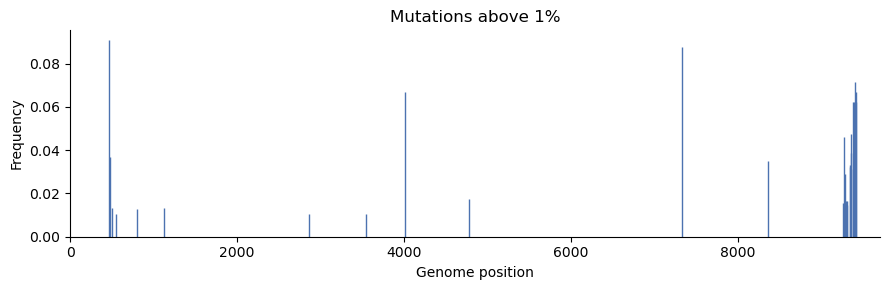

In [14]:
#Locations of mutations over 1%
x = df_1_perc['Position'].values
ymin = np.zeros(len(df_1_perc))
ymax = df_1_perc['Frequency'].values

fig, ax = plt.subplots(1,1,figsize=(9,3))
ax.vlines(x=x, ymin=ymin, ymax=ymax, colors="#4C72B0", linewidth=1)

#Format
ax.set_ylabel('Frequency')
ax.set_xlabel("Genome position")
ax.set_title("Mutations above 1%")
ax.set_xlim(0,9700)
ax.set_ylim(bottom=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(fig_path + "/ancestor_mutation_locations.pdf")
plt.show()

## Figure SI1

/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_45787/2955445077.py:36: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


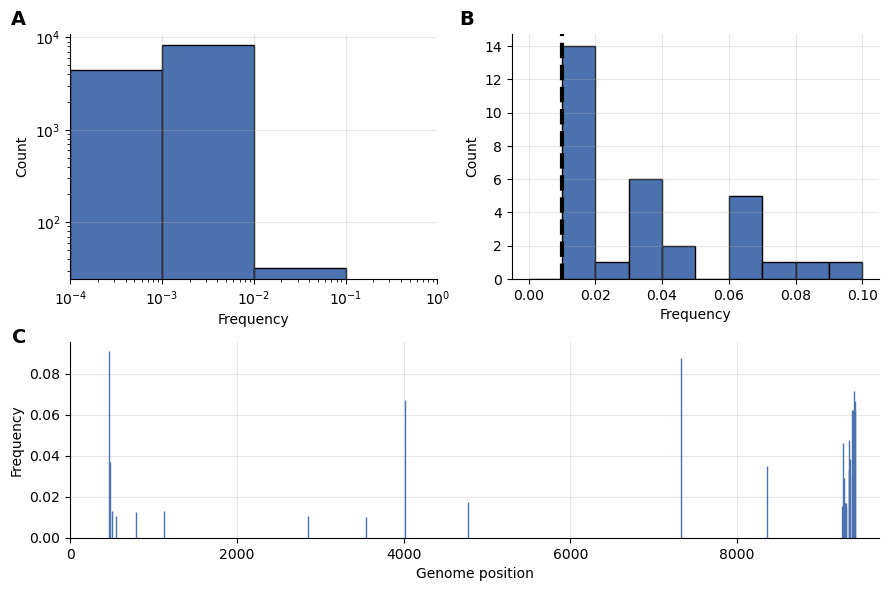

In [15]:
mosaic = [['A','B'],
          ['C','C']]

fig, ax = plt.subplot_mosaic(mosaic,figsize=(9, 6),height_ratios=[1,0.8],layout="constrained")

#Mutation frequencies
ax['A'].hist(df['Frequency'],bins=[0,0.0001,0.001,0.01,0.1],color="#4C72B0",edgecolor='black')
ax['A'].set_xlabel('Frequency')
ax['A'].set_ylabel('Count')
ax['A'].set_xscale('log')
ax['A'].set_yscale('log')
ax['A'].set_xlim(0.0001,1)
ax['A'].text(-0.12, 1.1, 'A', transform=ax['A'].transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

#Mutation frequencies above 1%
ax['B'].hist(df_1_perc['Frequency'],bins=np.linspace(0,0.1,11),color="#4C72B0",edgecolor='black')
ax['B'].axvline(x=0.01, color='black', linestyle='--', linewidth=3)
ax['B'].set_xlabel('Frequency')
ax['B'].set_ylabel('Count')
ax['B'].text(1.1, 1.1, 'B', transform=ax['A'].transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

#Mutation locations
ax['C'].vlines(x=x, ymin=ymin, ymax=ymax, colors="#4C72B0", linewidth=1)
ax['C'].set_ylabel('Frequency')
ax['C'].set_xlabel("Genome position")
ax['C'].set_xlim(0,9700)
ax['C'].set_ylim(bottom=0)
ax['C'].text(-0.12, -0.2, 'C', transform=ax['A'].transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

#Format
for ax in [ax['A'],ax['B'],ax['C']]:
    ax.grid(alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(fig_path + "/Figure_SI1.pdf")
plt.show()